# Spectral Signatures of Sector Bubbles: AI Era vs Dot-Com
## A Correlation Structure Analysis Using Fama-French 49 Industry Portfolios

**Author:** Aymane El Amrani  
**Date:** October 2026

---

## Abstract

I test whether the current AI sector exhibits the correlation structure signatures observed during the dot-com bubble (1997–2002). Using spectral analysis of rolling correlation matrices on Fama-French 49 industry portfolios — following Buccheri, Marmi & Mantegna (2013) — I compare three diagnostic metrics across both eras: dominant eigenvalue evolution (λ₁), intra-sector vs cross-sector correlation gap (herding), and second-mode eigenvector loadings (λ₂ decoupling). I find that while AI-adjacent industries show elevated within-group correlation, the defining spectral signature of the dot-com bubble — a clean tech-vs-rest decoupling in λ₂ — is absent in the AI era. The results suggest the current AI enthusiasm, as of late 2026, does not replicate the correlation regime that preceded the dot-com crash.

## 1. Introduction & Motivation

The rapid ascent of artificial intelligence stocks since 2023 has drawn frequent comparison to the dot-com bubble of the late 1990s. NVIDIA's capitalization surpassed $5 trillion, AI-adjacent companies saw triple-digit returns, and a handful of technology names began dominating index performance. The parallel is tempting, and widely repeated in financial media.

**But is it accurate?** Popular comparisons typically rely on price charts and valuation multiples. Most of the time, these are just noisy, context-dependent, and easy to cherry-pick. A more structural question is whether the correlation regime of today's market resembles the one that preceded the dot-com crash.

During a sector bubble, a distinctive pattern emerges in the correlation structure of asset returns. The bubble sector begins to move as a tightly correlated block — **herding** — while simultaneously **decoupling from the rest of the market.** This creates a measurable spectral signature: the second eigenvalue (λ₂) of the rolling correlation matrix spikes, and its associated eigenvector splits cleanly into the bubble sector versus everything else. Buccheri, Marmi & Mantegna (2013) documented this pattern in the dot-com era using spectral decomposition of correlation matrices.

In this study, I apply the same methodology to both periods. Using Fama-French 49 industry portfolios, I compute rolling correlation matrices and track the diagnostic metrics across the dot-com era (1997–2002) and the AI era (2023–2026): dominant eigenvalue share (λ₁), intra-sector versus cross-sector correlation gap, and second-mode eigenvector loadings.

**If the AI boom is structurally similar to the dot-com bubble, these metrics should show comparable signatures.**

## 2. Data

I use the Fama-French 49 industry portfolios, obtained from Kenneth French's data library. These portfolios aggregate all CRSP-listed stocks into 49 industry groups based on SIC codes, providing daily value-weighted returns. The dataset is widely used in empirical finance research for two reasons: it is survivorship-bias-free (delisted firms remain in the historical record), and its industry classification is consistent across decades, enabling direct cross-era comparison.

I analyze two periods:
- **Dot-com era:** January 1997 – December 2002, capturing the full bubble formation, peak and crash.
- **AI era:** January 2023 – October 2026, capturing the current AI-driven market regime.

Both periods use the same 49-industry structure, ensuring an apples-to-apples comparison. An earlier version of this analysis used individual AI-adjacent stocks (NVDA, MSFT, META, etc.) for the AI era, but the difference in data granularity introduced systematic noise differences that complicated interpretation. I retain the individual stock analysis as a supplementary exercise but base all cross-era conclusions on the Fama-French data.

All returns are converted from percentages to decimals. No additional filtering or cleaning is applied.

## 3. Methodology

### Rolling Correlation Matrices

For each period, I compute rolling Pearson correlation matrices over a 60-trading-day window (approximately 3 calendar months). At each time step *t*, the correlation matrix is constructed from the returns of all 49 industries over the window [*t*−60, *t*]. This produces a time series of 49×49 symmetric positive-definite matrices.

### Spectral Decomposition

Each correlation matrix is decomposed into its eigenvalues and eigenvectors using `scipy.linalg.eigh`, optimized for symmetric matrices. Eigenvalues are sorted in descending order. The key quantities:

- **λ₁ (first eigenvalue)**: Measures the fraction of total variance explained by the dominant co-movement factor — effectively, "how much is the whole market moving together." Expressed as λ₁/N × 100, where N=49.
- **λ₂ (second eigenvalue)**: Captures the strongest residual pattern after removing the market mode. A spike in λ₂ indicates a secondary structure — typically one group of industries diverging from another.
- **Eigenvector loadings of λ₂**: The 49 components of the second eigenvector reveal which industries are pulling apart. Positive and negative loadings identify the two opposing groups.

### Diagnostic Metrics

I track three metrics across both eras:

1. **Eigenvalue evolution** — λ₁/N and λ₂/N as percentages over time, measuring market-wide co-movement and sector decoupling strength.
2. **Herding gap** — The difference between average intra-tech correlation and average tech-vs-non-tech correlation, computed at each rolling window. Tech industries are defined as: Softw, Hardw, Chips, Telcm, BusSv, and LabEq. A rising gap indicates the tech sector moving together while pulling away from the broader market.
3. **λ₂ eigenvector loadings** — Examined at the peak λ₂ date for each era to identify which industries drive the decoupling mode.

### Window Validation

To confirm that results are not an artifact of the 60-day window choice, I repeat the herding gap analysis with windows of 30, 45, 60, 90, and 120 trading days. Results are qualitatively stable across all window sizes.

### Cross-Era Comparison

Because the two periods differ in length, time-series comparisons are plotted against trading days from the start of each period rather than calendar dates. Where direct overlay is needed, metrics are z-score normalized to account for differences in scale.

---
## 4. Setup & Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import linalg
import pandas_datareader as web
import warnings
warnings.filterwarnings("ignore")

# Plot styling
plt.rcParams.update({
    "figure.figsize": (14, 6),
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
})

COLORS = {
    "dotcom": "#e74c3c",
    "ai": "#3498db",
    "neutral": "#2c3e50",
    "highlight": "#f39c12",
}

print("All imports loaded")

All imports loaded


## 5. Data Loading

In [2]:
# Fama-French 49 — Dot-Com Era
ff49 = web.DataReader("49_Industry_Portfolios_daily", "famafrench",
                      start="1997-01-01", end="2002-12-31")[0]
ff49 = ff49 / 100
print(f"Dot-Com — Shape: {ff49.shape}, Range: {ff49.index[0]} to {ff49.index[-1]}")

# Fama-French 49 — AI Era
ff49_ai = web.DataReader("49_Industry_Portfolios_daily", "famafrench",
                         start="2023-01-01")[0]
ff49_ai = ff49_ai / 100
print(f"AI Era  — Shape: {ff49_ai.shape}, Range: {ff49_ai.index[0]} to {ff49_ai.index[-1]}")

Dot-Com — Shape: (1509, 49), Range: 1997-01-02 to 2002-12-31
AI Era  — Shape: (939, 49), Range: 2023-01-03 to 2026-09-30


## 6. Core Function

In [3]:
def rolling_spectral(returns, window=60):
    """
    Compute rolling eigenvalues/eigenvectors of the correlation matrix.

    Parameters:
        returns: DataFrame of asset returns
        window: rolling window size in trading days

    Returns:
        dates: list of dates for each window
        eigenvalues: array (T, N) — eigenvalues in descending order
        eigenvectors: array (T, N, N) — corresponding eigenvectors
    """
    dates, eigenvalues, eigenvectors = [], [], []

    for i in range(window, len(returns)):
        chunk = returns.iloc[i-window:i]
        corr = chunk.corr().values
        vals, vecs = linalg.eigh(corr)
        vals = vals[::-1]
        vecs = vecs[:, ::-1]
        dates.append(returns.index[i])
        eigenvalues.append(vals)
        eigenvectors.append(vecs)

    return dates, np.array(eigenvalues), np.array(eigenvectors)

# Tech sector definition (consistent across both eras)
tech = ["Softw", "Hardw", "Chips", "Telcm", "BusSv", "LabEq"]

print("Core function defined")
print(f"Tech group: {tech}")

Core function defined
Tech group: ['Softw', 'Hardw', 'Chips', 'Telcm', 'BusSv', 'LabEq']


---
## 7. Results

### 7.1 Dot-Com Baseline (1997–2002)

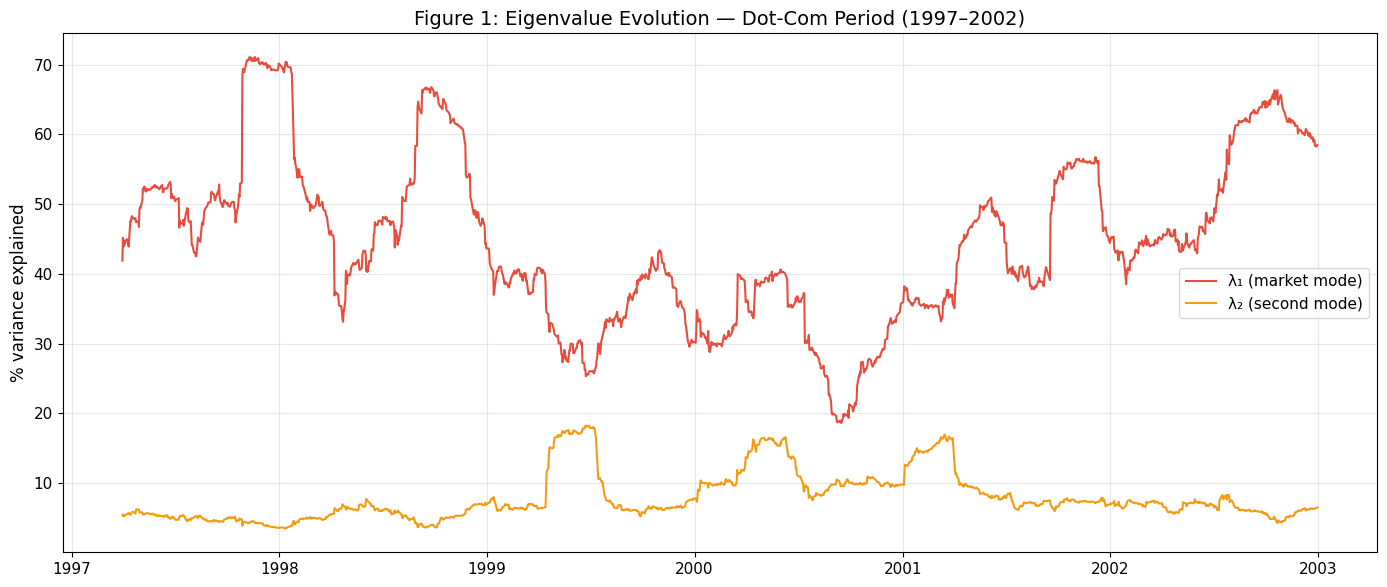

In [4]:
# Spectral decomposition — Dot-Com
dates_dc, evals_dc, evecs_dc = rolling_spectral(ff49)
dates_dc_ts = pd.to_datetime([str(d) for d in dates_dc])
N = ff49.shape[1]  # 49

fig, ax = plt.subplots()
ax.plot(dates_dc_ts, evals_dc[:, 0]/N*100,
        label="λ₁ (market mode)", color=COLORS["dotcom"])
ax.plot(dates_dc_ts, evals_dc[:, 1]/N*100,
        label="λ₂ (second mode)", color=COLORS["highlight"])
ax.set_ylabel("% variance explained")
ax.set_title("Figure 1: Eigenvalue Evolution — Dot-Com Period (1997–2002)")
ax.legend()
plt.tight_layout()
plt.show()

**λ₁** captures market-wide co-movement — how much all 49 industries move together. **λ₂** captures the strongest secondary pattern. During the dot-com bubble, λ₂ spikes indicate a group of industries pulling away from the rest.

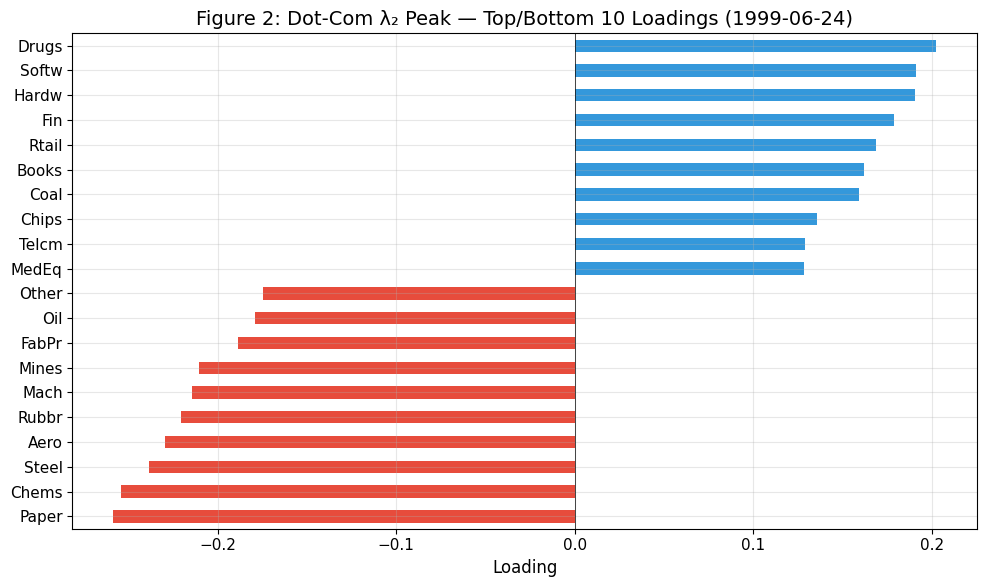

In [5]:
# λ₂ eigenvector loadings at peak — Dot-Com
peak_dc = np.argmax(evals_dc[:, 1])
loadings_dc = pd.Series(evecs_dc[peak_dc, :, 1], index=ff49.columns)

top_dc = pd.concat([loadings_dc.nsmallest(10), loadings_dc.nlargest(10)])
top_dc.sort_values().plot.barh(figsize=(10, 6),
    color=[COLORS["dotcom"] if v < 0 else COLORS["ai"] for v in top_dc.sort_values()])
plt.title(f"Figure 2: Dot-Com λ₂ Peak — Top/Bottom 10 Loadings ({dates_dc[peak_dc]})")
plt.xlabel("Loading")
plt.axvline(x=0, color="black", linewidth=0.5)
plt.tight_layout()
plt.show()

The eigenvector loadings at the λ₂ peak reveal a clean split: **tech sectors** (Softw, Hardw, Chips, Telcm) load on one side, while **old-economy industrials** (Paper, Chems, Steel, Aero) load on the other. This is the spectral signature of a sector bubble — one group decoupling from the rest.

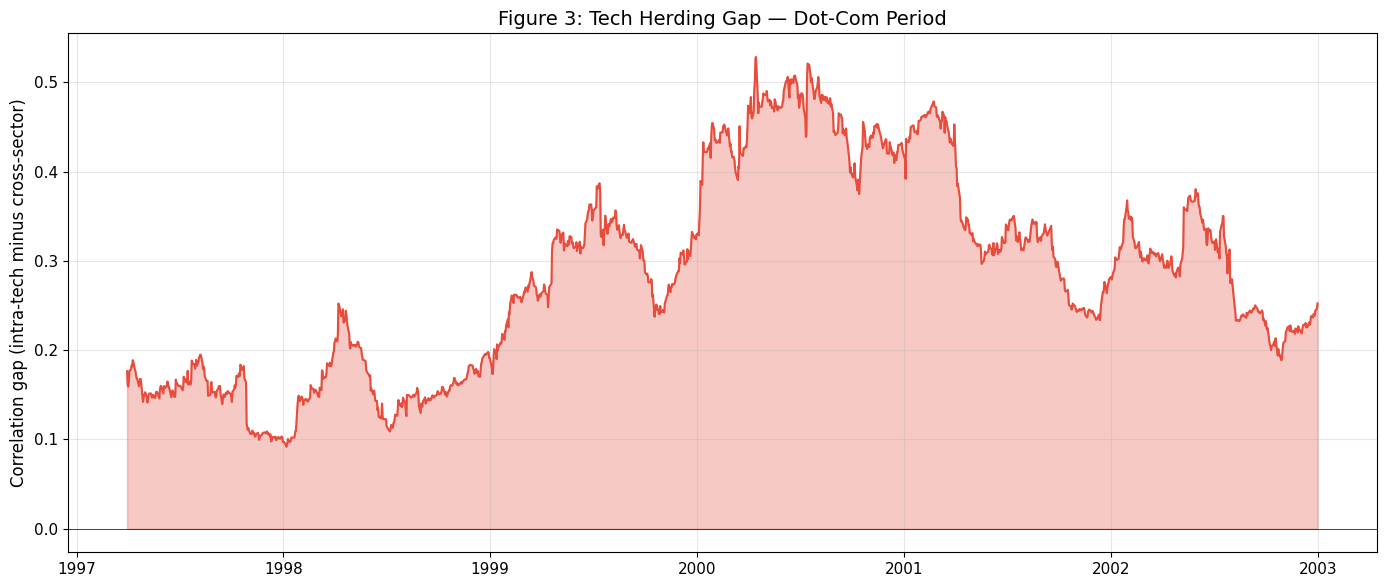

In [6]:
# Herding gap — Dot-Com
non_tech = [c for c in ff49.columns if c not in tech]

intra_tech_dc, cross_dc = [], []
for i in range(60, len(ff49)):
    corr = ff49.iloc[i-60:i].corr()
    tc = corr.loc[tech, tech].values
    mask_t = ~np.eye(len(tech), dtype=bool)
    intra_tech_dc.append(tc[mask_t].mean())
    cross_dc.append(corr.loc[tech, non_tech].values.mean())

gap_dc = np.array(intra_tech_dc) - np.array(cross_dc)

fig, ax = plt.subplots()
ax.plot(dates_dc_ts, gap_dc, color=COLORS["dotcom"])
ax.fill_between(dates_dc_ts, gap_dc, alpha=0.3, color=COLORS["dotcom"])
ax.set_ylabel("Correlation gap (intra-tech minus cross-sector)")
ax.set_title("Figure 3: Tech Herding Gap — Dot-Com Period")
ax.axhline(y=0, color="black", linewidth=0.5)
plt.tight_layout()
plt.show()

The herding gap rises steadily from ~0.15 in 1997 to ~0.45 by 2000 — tech industries were increasingly moving as a block while decoupling from the rest. After the crash (March 2000), the gap persists before gradually declining through 2002.

---
### 7.2 AI Era (2023–2026)

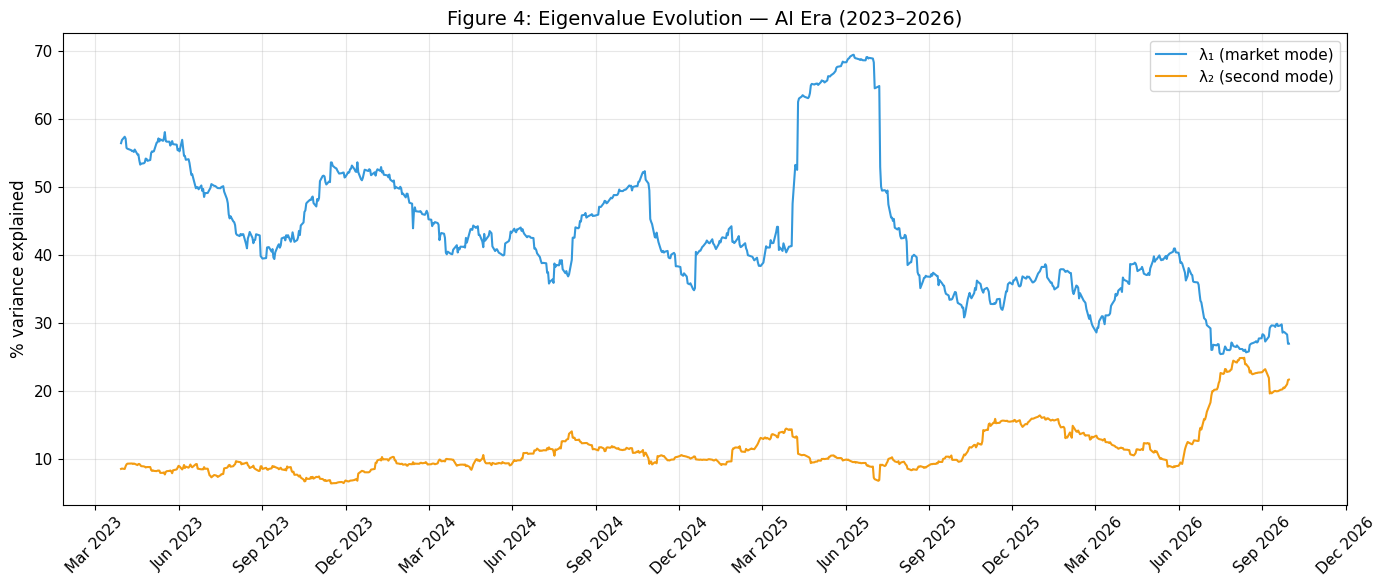

In [7]:
# Spectral decomposition — AI Era
dates_ai, evals_ai, evecs_ai = rolling_spectral(ff49_ai)
dates_ai_ts = pd.to_datetime([str(d) for d in dates_ai])

fig, ax = plt.subplots()
ax.plot(dates_ai_ts, evals_ai[:, 0]/N*100,
        label="λ₁ (market mode)", color=COLORS["ai"])
ax.plot(dates_ai_ts, evals_ai[:, 1]/N*100,
        label="λ₂ (second mode)", color=COLORS["highlight"])
ax.set_ylabel("% variance explained")
ax.set_title("Figure 4: Eigenvalue Evolution — AI Era (2023–2026)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

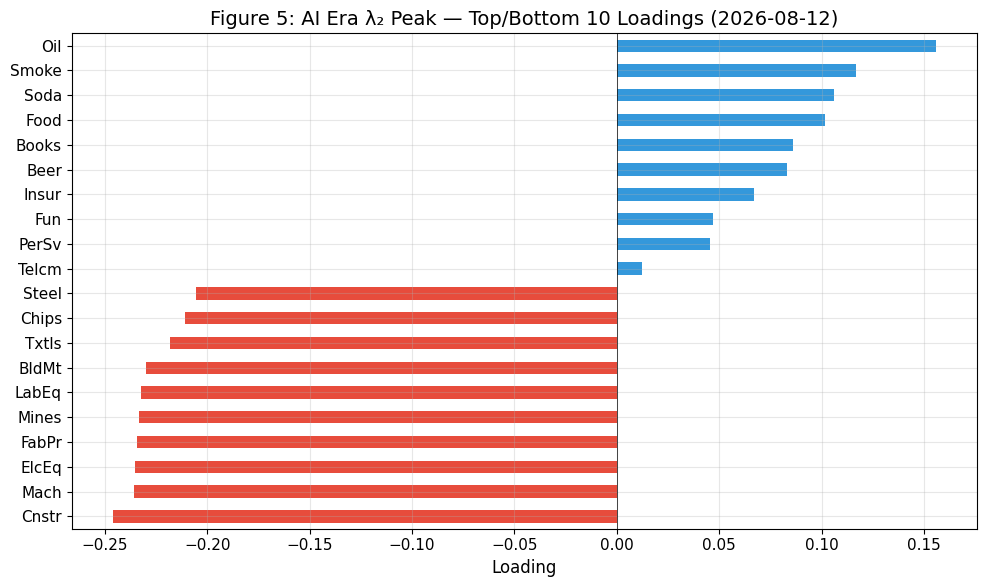

In [8]:
# λ₂ eigenvector loadings at peak — AI Era
peak_ai = np.argmax(evals_ai[:, 1])
loadings_ai = pd.Series(evecs_ai[peak_ai, :, 1], index=ff49_ai.columns)

top_ai = pd.concat([loadings_ai.nsmallest(10), loadings_ai.nlargest(10)])
top_ai.sort_values().plot.barh(figsize=(10, 6),
    color=[COLORS["dotcom"] if v < 0 else COLORS["ai"] for v in top_ai.sort_values()])
plt.title(f"Figure 5: AI Era λ₂ Peak — Top/Bottom 10 Loadings ({dates_ai[peak_ai]})")
plt.xlabel("Loading")
plt.axvline(x=0, color="black", linewidth=0.5)
plt.tight_layout()
plt.show()

**Key difference:** The AI era λ₂ eigenvector does NOT show a tech-vs-rest split. Instead, it picks up a **defensive/commodity vs cyclical** rotation — Oil, Smoke, Soda on one side; Construction, Machinery, Electrical Equipment on the other. The AI-adjacent sectors (Softw, Chips, Telcm) do not dominate either side. The defining spectral signature of the dot-com bubble is absent.

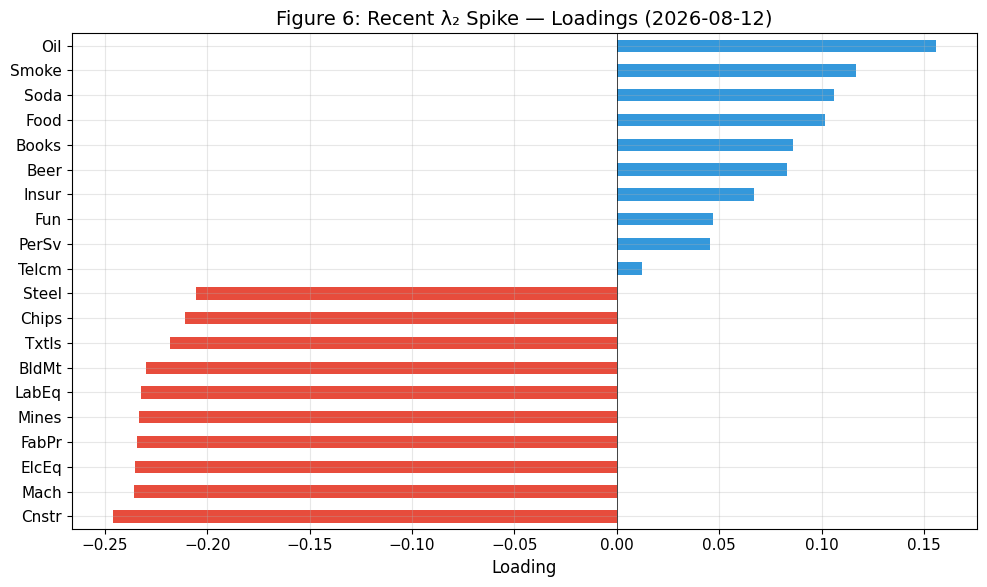

In [9]:
# Recent λ₂ spike — what's driving it?
recent_start = len(evals_ai) - 60  # last ~3 months
recent_peak = recent_start + np.argmax(evals_ai[recent_start:, 1])
loadings_recent = pd.Series(evecs_ai[recent_peak, :, 1], index=ff49_ai.columns)

top_r = pd.concat([loadings_recent.nsmallest(10), loadings_recent.nlargest(10)])
top_r.sort_values().plot.barh(figsize=(10, 6),
    color=[COLORS["dotcom"] if v < 0 else COLORS["ai"] for v in top_r.sort_values()])
plt.title(f"Figure 6: Recent λ₂ Spike — Loadings ({dates_ai[recent_peak]})")
plt.xlabel("Loading")
plt.axvline(x=0, color="black", linewidth=0.5)
plt.tight_layout()
plt.show()

The recent λ₂ spike (mid-2026) shows the same defensive-vs-cyclical pattern as the overall AI-era peak — **not** a tech decoupling. Despite the rising magnitude, the eigenvector structure confirms this is driven by macroeconomic rotation (rate expectations, recession concerns), not tech-specific speculation.

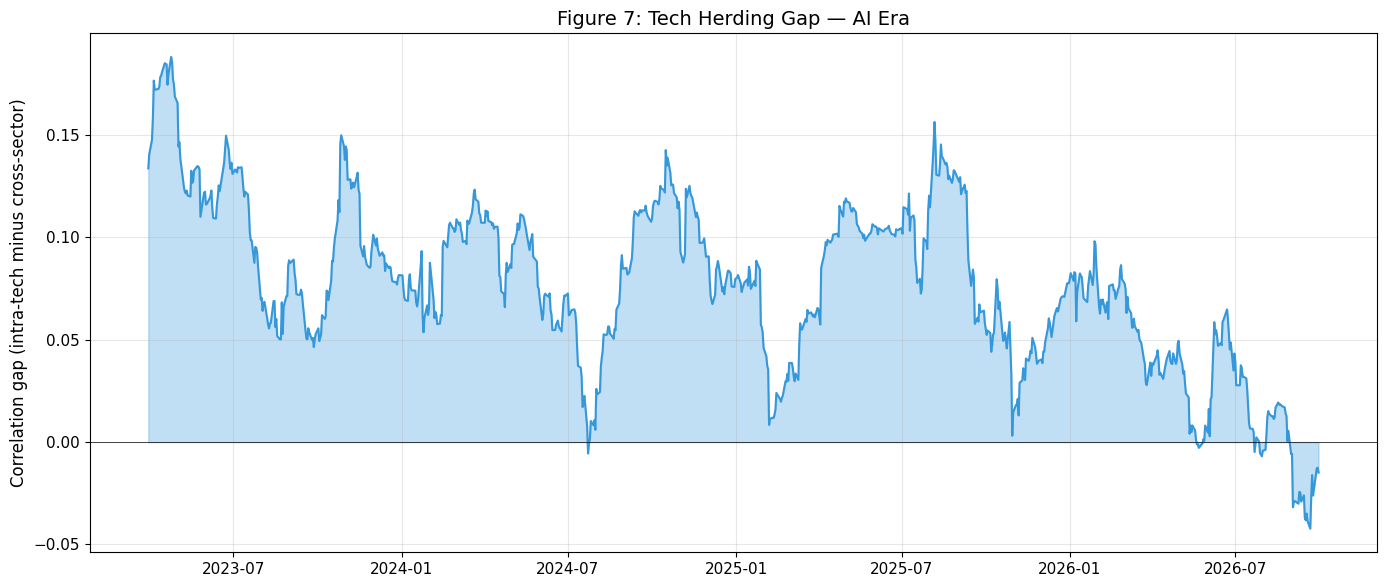

In [10]:
# Herding gap — AI Era
non_tech_ai = [c for c in ff49_ai.columns if c not in tech]

intra_tech_ai, cross_ai = [], []
for i in range(60, len(ff49_ai)):
    corr = ff49_ai.iloc[i-60:i].corr()
    tc = corr.loc[tech, tech].values
    mask_t = ~np.eye(len(tech), dtype=bool)
    intra_tech_ai.append(tc[mask_t].mean())
    cross_ai.append(corr.loc[tech, non_tech_ai].values.mean())

gap_ai = np.array(intra_tech_ai) - np.array(cross_ai)

fig, ax = plt.subplots()
ax.plot(dates_ai_ts, gap_ai, color=COLORS["ai"])
ax.fill_between(dates_ai_ts, gap_ai, alpha=0.3, color=COLORS["ai"])
ax.set_ylabel("Correlation gap (intra-tech minus cross-sector)")
ax.set_title("Figure 7: Tech Herding Gap — AI Era")
ax.axhline(y=0, color="black", linewidth=0.5)
plt.tight_layout()
plt.show()

The AI-era herding gap fluctuates between 0.05 and 0.20 with no sustained upward trend — completely unlike the dot-com's steady climb to 0.45. In the most recent months, the gap turns **negative**, meaning tech industries are actually *less* correlated with each other than with non-tech — the opposite trajectory from a bubble buildup.

---
### 7.3 Cross-Era Comparison

The three-panel figure below overlays both eras on the same axes, aligned by trading days from the start of each period.

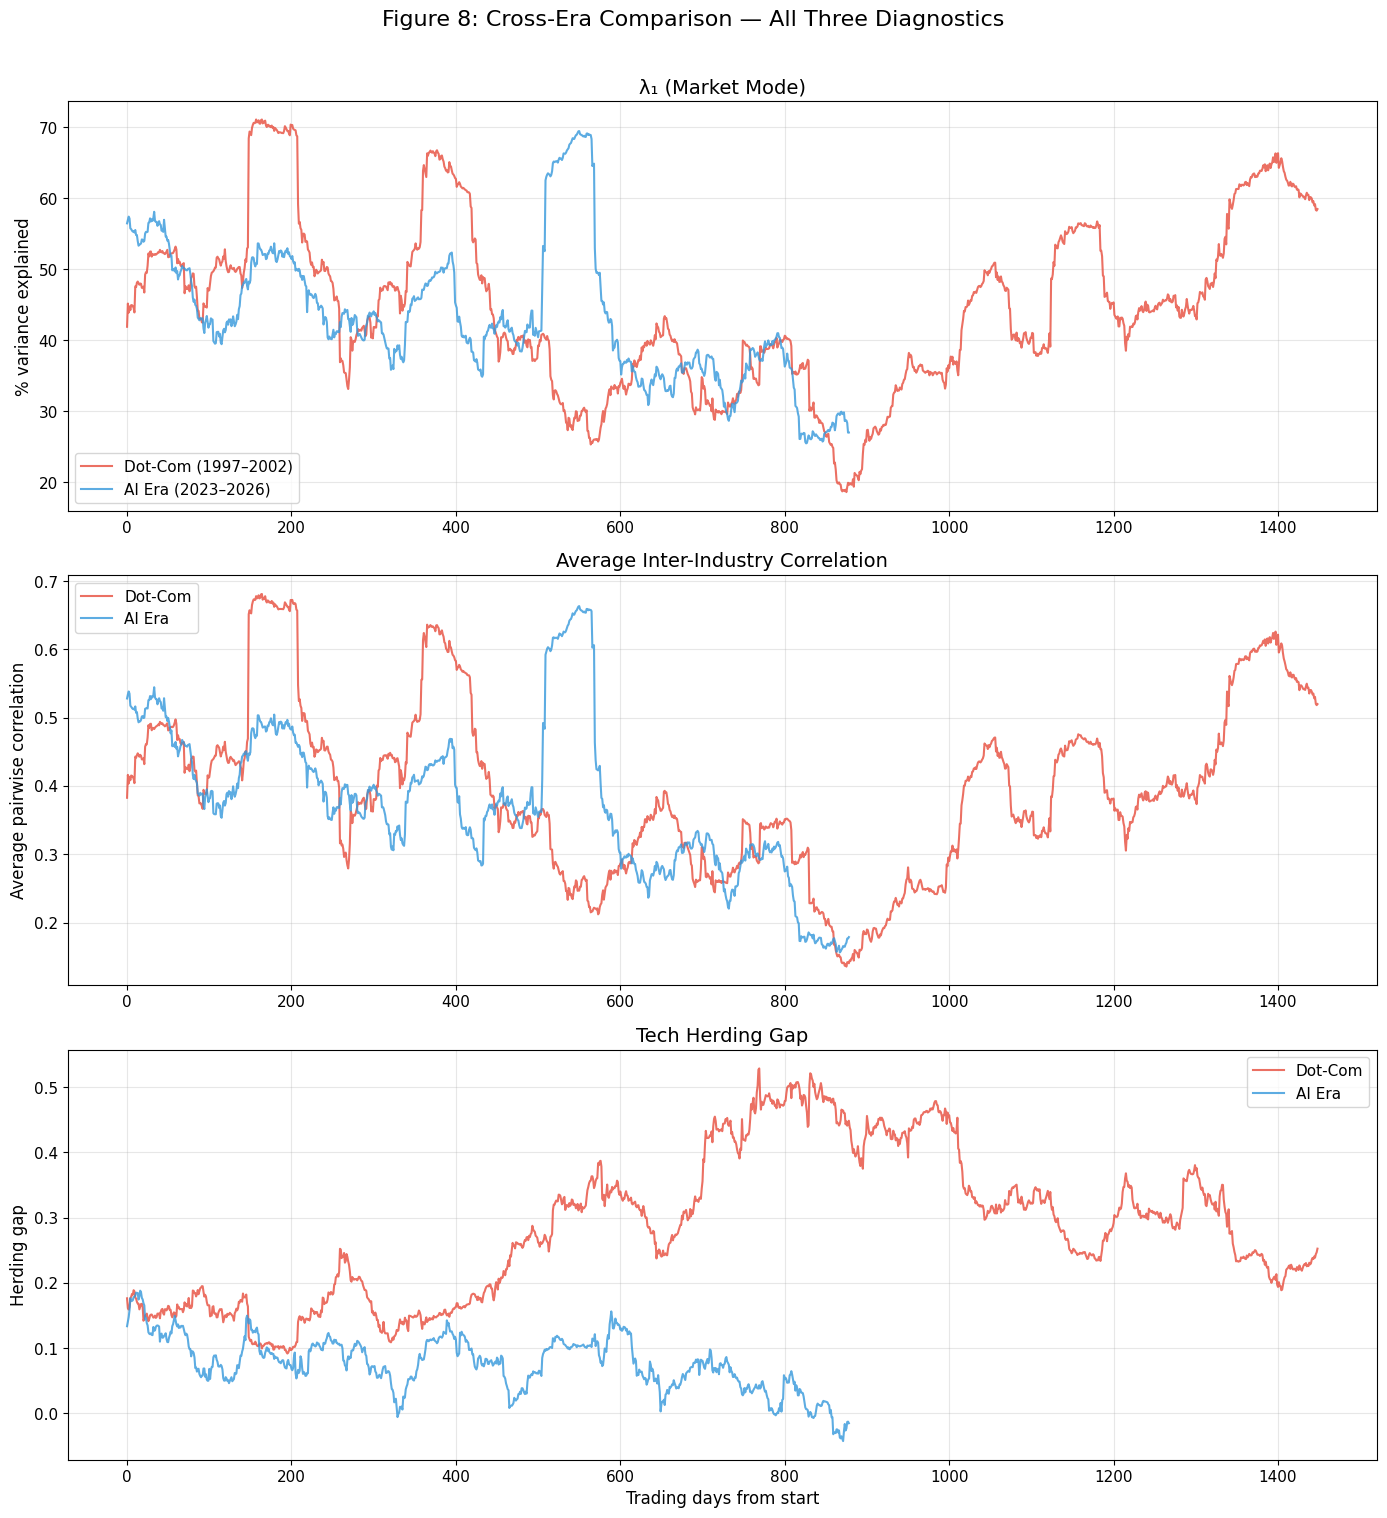

In [11]:
# Average correlation for both eras (needed for comparison)
avg_corr_dc = []
for i in range(60, len(ff49)):
    corr = ff49.iloc[i-60:i].corr().values
    mask = ~np.eye(corr.shape[0], dtype=bool)
    avg_corr_dc.append(corr[mask].mean())

avg_corr_ai = []
for i in range(60, len(ff49_ai)):
    corr = ff49_ai.iloc[i-60:i].corr().values
    mask = ~np.eye(corr.shape[0], dtype=bool)
    avg_corr_ai.append(corr[mask].mean())

# Three-panel comparison
fig, axes = plt.subplots(3, 1, figsize=(14, 15))

# Panel 1: λ₁
ax = axes[0]
ax.plot(range(len(evals_dc)), evals_dc[:, 0]/N*100,
        label="Dot-Com (1997–2002)", color=COLORS["dotcom"], alpha=0.8)
ax.plot(range(len(evals_ai)), evals_ai[:, 0]/N*100,
        label="AI Era (2023–2026)", color=COLORS["ai"], alpha=0.8)
ax.set_ylabel("% variance explained")
ax.set_title("λ₁ (Market Mode)")
ax.legend()

# Panel 2: Average correlation
ax = axes[1]
ax.plot(range(len(avg_corr_dc)), avg_corr_dc,
        label="Dot-Com", color=COLORS["dotcom"], alpha=0.8)
ax.plot(range(len(avg_corr_ai)), avg_corr_ai,
        label="AI Era", color=COLORS["ai"], alpha=0.8)
ax.set_ylabel("Average pairwise correlation")
ax.set_title("Average Inter-Industry Correlation")
ax.legend()

# Panel 3: Herding gap
ax = axes[2]
ax.plot(range(len(gap_dc)), gap_dc,
        label="Dot-Com", color=COLORS["dotcom"], alpha=0.8)
ax.plot(range(len(gap_ai)), gap_ai,
        label="AI Era", color=COLORS["ai"], alpha=0.8)
ax.set_ylabel("Herding gap")
ax.set_title("Tech Herding Gap")
ax.set_xlabel("Trading days from start")
ax.legend()

plt.suptitle("Figure 8: Cross-Era Comparison — All Three Diagnostics", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

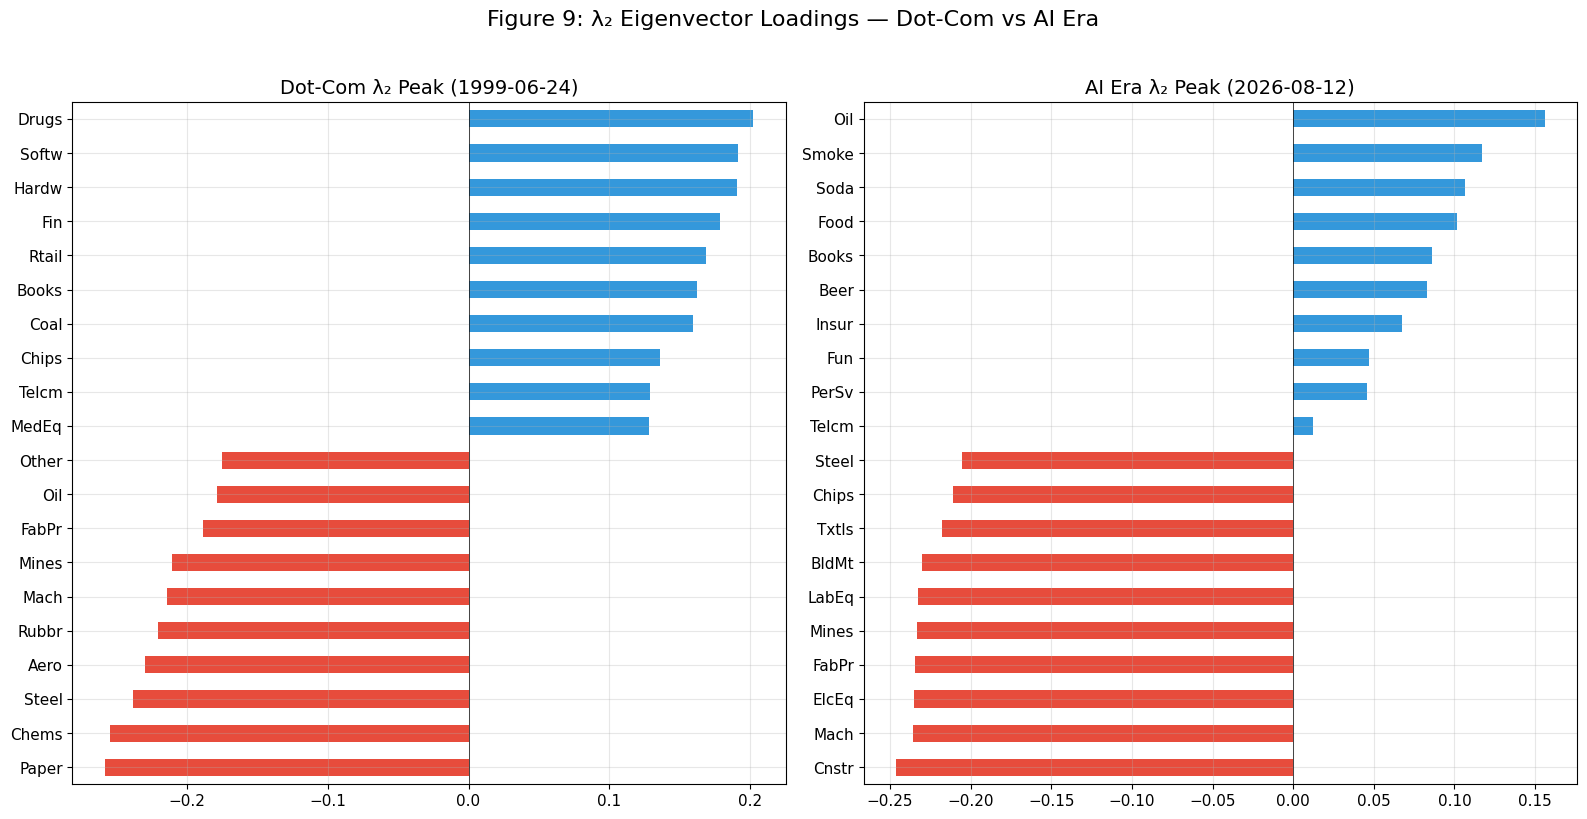

In [12]:
# λ₂ eigenvector comparison — side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# Dot-com peak
top_dc_plot = pd.concat([loadings_dc.nsmallest(10), loadings_dc.nlargest(10)])
top_dc_plot.sort_values().plot.barh(ax=ax1,
    color=[COLORS["dotcom"] if v < 0 else COLORS["ai"] for v in top_dc_plot.sort_values()])
ax1.set_title(f"Dot-Com λ₂ Peak ({dates_dc[peak_dc]})")
ax1.axvline(x=0, color="black", linewidth=0.5)

# AI era peak
top_ai_plot = pd.concat([loadings_ai.nsmallest(10), loadings_ai.nlargest(10)])
top_ai_plot.sort_values().plot.barh(ax=ax2,
    color=[COLORS["dotcom"] if v < 0 else COLORS["ai"] for v in top_ai_plot.sort_values()])
ax2.set_title(f"AI Era λ₂ Peak ({dates_ai[peak_ai]})")
ax2.axvline(x=0, color="black", linewidth=0.5)

plt.suptitle("Figure 9: λ₂ Eigenvector Loadings — Dot-Com vs AI Era", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

---
### 7.4 Window Validation

To confirm that the herding gap results are not an artifact of the 60-day window choice, I repeat the analysis with windows of 30, 45, 60, 90, and 120 trading days.

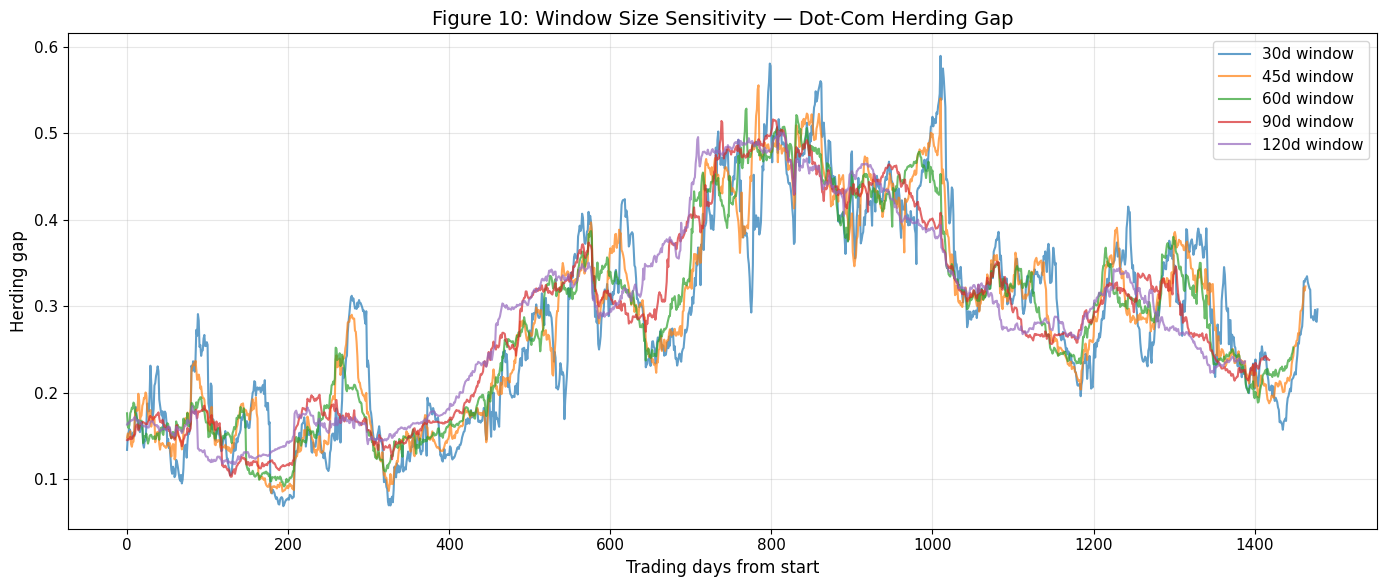

In [13]:
windows = [30, 45, 60, 90, 120]

fig, ax = plt.subplots(figsize=(14, 6))
for w in windows:
    intra, cr = [], []
    for i in range(w, len(ff49)):
        corr = ff49.iloc[i-w:i].corr()
        tc = corr.loc[tech, tech].values
        m = ~np.eye(len(tech), dtype=bool)
        intra.append(tc[m].mean())
        cr.append(corr.loc[tech, non_tech].values.mean())
    g = np.array(intra) - np.array(cr)
    ax.plot(range(len(g)), g, label=f"{w}d window", alpha=0.7)

ax.set_xlabel("Trading days from start")
ax.set_ylabel("Herding gap")
ax.set_title("Figure 10: Window Size Sensitivity — Dot-Com Herding Gap")
ax.legend()
plt.tight_layout()
plt.show()

All window sizes produce qualitatively identical results: the herding gap rises from ~0.15 to ~0.45–0.50 during the bubble, with the same timing. The 30-day window is noisier (shorter window = more variance), and the 120-day window is smoother, but the trend is stable. This validates the 60-day window as a robust choice.

---
## 8. Supplementary: Individual Stock Analysis

As an additional exercise, I repeat the herding gap analysis using individual AI-adjacent stocks (2023–present) rather than Fama-French industry portfolios. This provides higher granularity but is not directly comparable to the dot-com baseline due to the difference in data construction (individual stocks vs averaged portfolios).

In [14]:
import yfinance as yf

tickers = {
    "AI_adjacent": ["NVDA","AMD","SMCI","AVGO","MRVL","ARM","MSFT","GOOG",
                     "META","AMZN","CRM","PLTR","AI","SNOW","MU"],
    "Non_AI_tech": ["AAPL","CSCO","ORCL","IBM","INTC","HPQ","TXN","QCOM"],
    "Financials":  ["JPM","GS","BAC","BLK","MS"],
    "Healthcare":  ["JNJ","UNH","PFE","ABT","LLY"],
    "Energy":      ["XOM","CVX","COP","SLB"],
    "Consumer_Ind":["PG","KO","CAT","MMM","WMT"],
    "Safe_haven":  ["GLD","TLT","VZ"]
}

all_tickers = [t for group in tickers.values() for t in group]
prices = yf.download(all_tickers, start="2023-01-01")["Close"]
returns_stocks = prices.pct_change().dropna()
print(f"Individual stocks — Shape: {returns_stocks.shape}")

[*********************100%***********************]  45 of 45 completed


Individual stocks — Shape: (785, 45)


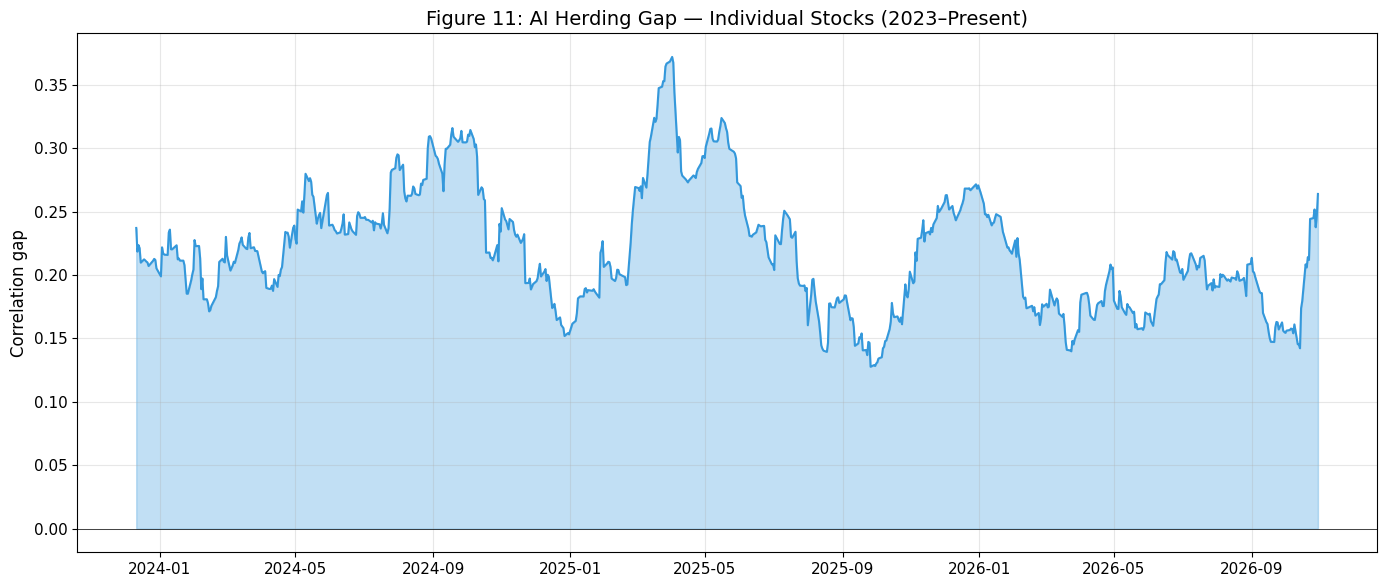

In [15]:
ai_tickers = tickers["AI_adjacent"]
non_ai_tickers = [t for t in all_tickers if t not in ai_tickers]

intra_ai, cross_ai_s = [], []
for i in range(60, len(returns_stocks)):
    corr = returns_stocks.iloc[i-60:i].corr()
    ai_corr = corr.loc[ai_tickers, ai_tickers].values
    mask_ai = ~np.eye(len(ai_tickers), dtype=bool)
    intra_ai.append(ai_corr[mask_ai].mean())
    cross_ai_s.append(corr.loc[ai_tickers, non_ai_tickers].values.mean())

dates_s_ts = returns_stocks.index[60:]
gap_stocks = np.array(intra_ai) - np.array(cross_ai_s)

fig, ax = plt.subplots()
ax.plot(dates_s_ts, gap_stocks, color=COLORS["ai"])
ax.fill_between(dates_s_ts, gap_stocks, alpha=0.3, color=COLORS["ai"])
ax.set_ylabel("Correlation gap")
ax.set_title("Figure 11: AI Herding Gap — Individual Stocks (2023–Present)")
ax.axhline(y=0, color="black", linewidth=0.5)
plt.tight_layout()
plt.show()

The individual stock analysis shows a noisier herding gap, as expected from non-averaged data. The general level is comparable to the Fama-French AI era analysis, confirming that the choice of dataset does not change the conclusion — only the noise level.

---
## 9. Discussion

The central finding of this study is negative: the AI era does not reproduce the correlation regime that characterized the dot-com bubble. While the popular narrative frames AI as "dot-com 2.0," the spectral structure of the market tells a different story across all three diagnostics.

During the dot-com period, the market exhibited a textbook bubble signature — tech industries herded into a tightly correlated block (herding gap rising from 0.15 to 0.45), while the second eigenvalue spiked and its eigenvector split cleanly along tech-vs-old-economy lines. This pattern was sustained over nearly three years before the crash, building steadily rather than appearing as a brief fluctuation.

The AI era shows none of this. The herding gap remains flat and low (0.05–0.15), with no upward trend. The λ₂ eigenvector, even at its peak, separates defensive sectors from cyclicals — not tech from the rest. And in the most recent months, the herding gap turns negative, suggesting that tech industries are losing coherence as a correlated block.

Why might this be? Several structural differences between the two eras could explain the divergence:

First, **AI adoption is cross-sectoral**. The dot-com boom was concentrated in a narrow set of technology and telecom firms. AI, by contrast, is being adopted across healthcare, finance, energy, and manufacturing. This diffuses the "tech" signal across the entire market rather than concentrating it in one block, which is consistent with the absence of a clean tech-vs-rest eigenvector split.

Second, **market structure has evolved**. The proliferation of ETFs, algorithmic trading, and passive investment has changed how correlations behave. The market mode (λ₁) is structurally higher today than in the late 1990s, which may compress the space available for sector-level decoupling signals in λ₂.

Finally, the rising λ₂ in late 2026 deserves attention. While its magnitude approaches levels seen in the dot-com period, the eigenvector structure reveals a defensive-vs-cyclical rotation — likely driven by macroeconomic uncertainty (rate expectations, recession concerns) rather than tech-specific speculation. This highlights an important methodological point: eigenvalue magnitude alone is insufficient to diagnose a bubble. The eigenvector structure — *who* is decoupling from *whom* — is what distinguishes a sector bubble from a macro-driven regime shift.

An important question this analysis cannot answer is **whether AI valuations are fundamentally justified**. This method detects *correlation herding*, not mispricing. The absence of a dot-com-style correlation regime does not mean AI stocks are fairly valued — it means the market is not treating them as a speculative bloc the way it treated internet stocks in 1998–2000. Whether the current AI investment cycle generates adequate returns remains an open empirical question for future work.

---
## 10. Limitations

**Industry-level granularity.** The Fama-French 49 industry portfolios aggregate individual firms into broad categories. A bubble concentrated in a handful of mega-cap names (NVIDIA, Microsoft, Meta) could be masked if the rest of their industry behaves normally. Individual-stock-level spectral analysis would provide finer resolution, though at the cost of a much larger and noisier correlation matrix.

**Single methodology.** I rely exclusively on eigenvalue decomposition of rolling correlation matrices. Other approaches — such as log-periodic power law models, measures of trading volume synchronization, or sentiment-based indicators — might detect bubble dynamics that correlation structure misses.

**Window sensitivity.** Although I validated results across multiple window sizes (30, 45, 60, 90, 120 days), the rolling window approach inherently smooths sharp transitions. A regime change occurring over a few trading days could be diluted within a 60-day window.

**Survivorship in the AI era.** While the Fama-French portfolios mitigate survivorship bias for the dot-com period, the AI era is still unfolding. If a correction occurs in the future, the current dataset captures only the buildup phase.

**Correlation is not valuation.** This method detects co-movement patterns, not mispricing. The dot-com bubble involved both extreme herding *and* extreme overvaluation. The absence of herding does not rule out overvaluation driven by other mechanisms. Conversely, the profitability of AI infrastructure companies (versus the deep losses of AI model companies) presents a more complex valuation picture than the dot-com era — one that correlation analysis alone cannot resolve.

**Stationarity assumption.** Rolling correlation implicitly assumes local stationarity within each window. In periods of market stress, correlations can shift abruptly, violating this assumption and potentially distorting the eigenvalue decomposition.

---
## 11. Conclusion

I applied spectral analysis of rolling correlation matrices to compare the market's correlation structure during the dot-com bubble (1997–2002) with the current AI era (2023–2026), using the Fama-French 49 industry portfolios to ensure a consistent, survivorship-bias-free comparison across both periods.

The dot-com bubble produced a clear and sustained spectral signature: the second eigenvalue rose steadily, its eigenvector split along tech-vs-non-tech lines, and the herding gap climbed from 0.15 to 0.45 over nearly three years before the crash. The AI era reproduces none of these patterns. The herding gap remains flat, the λ₂ eigenvector reflects macro-driven sector rotations rather than tech decoupling, and the most recent data shows the herding gap turning negative — tech industries losing coherence as a group.

These results do not settle whether AI stocks are overvalued. They do establish that the market is not treating AI as a speculative bloc in the way it treated internet stocks in 1998–2000. If a correction in AI valuations does occur, it is unlikely to follow the same correlation pathway as the dot-com crash.

Future work could extend this analysis in several directions: applying the same framework at the individual-stock level to detect concentration within industries, incorporating alternative bubble detection methods alongside spectral analysis, and revisiting this dataset as the AI investment cycle matures — particularly to test whether the negative herding gap persists or reverses.

---
## 12. References

1. Buccheri, G., Marmi, S., & Mantegna, R. N. (2013). Evolution of correlation structure of industrial indices of US equity markets. *Physical Review E*, 88, 012806. DOI: 10.1103/PhysRevE.88.012806
2. Fama, E. F., & French, K. R. (1997). Industry costs of equity. *Journal of Financial Economics*, 43(2), 153–193.
3. Laloux, L., Cizeau, P., Bouchaud, J.-P., & Potters, M. (1999). Noise dressing of financial correlation matrices. *Physical Review Letters*, 83, 1467–1470.